# Lab 19 Automation Bias and Trust in AI

**Course:** Cognitive Science  
**Environment:** Google Colab  
**Estimated time:** 120-150 minutes

## Learning objectives
- Measure appropriate reliance, over-reliance, and under-reliance.
- Distinguish trust from system accuracy.
- Test whether confidence displays change verification behavior.

## Theory in brief
Appropriate reliance means accepting useful advice and rejecting faulty advice. Automation bias appears when a user follows an incorrect recommendation without sufficient checking.

## Ethics and data handling
Use an anonymous participant code. This classroom activity is not a diagnostic test. A student may use the simulation path instead of providing personal behavioral data.

## Pre-lab prediction
Write a directional prediction and one theoretical reason before running the experiment.

**My prediction:** เมื่อระบบแสดงความมั่นใจสูง คนน่าจะยอมรับคำแนะนำมากขึ้นและ verify น้อยลง ทำให้เกิด over-reliance กับคำแนะนำที่ผิดแต่มั่นใจสูง


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
RNG = np.random.default_rng(42)
print('Environment ready')


Environment ready


In [2]:
# ===== Simulation path (แทน input ตามที่โจทย์อนุญาต) =====
cases = pd.DataFrame([
    {'id':1,'evidence':8,'system_advice':'HIGH','system_correct':1,'system_confidence':.92},
    {'id':2,'evidence':3,'system_advice':'HIGH','system_correct':0,'system_confidence':.88},
    {'id':3,'evidence':2,'system_advice':'LOW','system_correct':1,'system_confidence':.70},
    {'id':4,'evidence':9,'system_advice':'LOW','system_correct':0,'system_confidence':.95},
    {'id':5,'evidence':7,'system_advice':'HIGH','system_correct':1,'system_confidence':.62},
    {'id':6,'evidence':4,'system_advice':'LOW','system_correct':1,'system_confidence':.58}])

rng_sim = np.random.default_rng(67011212055 % 10000)
rows = []
for _, r in cases.iterrows():
    if r.system_confidence >= 0.85:
        action = 'A' if rng_sim.random() < 0.75 else 'V'
    elif r.system_confidence >= 0.65:
        action = rng_sim.choice(['A', 'V', 'R'], p=[0.4, 0.4, 0.2])
    else:
        action = rng_sim.choice(['V', 'R', 'A'], p=[0.45, 0.35, 0.20])
    rows.append({**r.to_dict(), 'action': action})
df = pd.DataFrame(rows)
df.to_csv('lab19_automation_trust.csv', index=False)
df


,id,evidence,system_advice,system_correct,system_confidence,action
0,1,8,HIGH,1,0.92,A
1,2,3,HIGH,0,0.88,V
2,3,2,LOW,1,0.70,A
3,4,9,LOW,0,0.95,V
4,5,7,HIGH,1,0.62,R
5,6,4,LOW,1,0.58,V


,rate
appropriate,0.833333
over_reliance,0.000000
under_reliance,0.166667
verified,0.500000


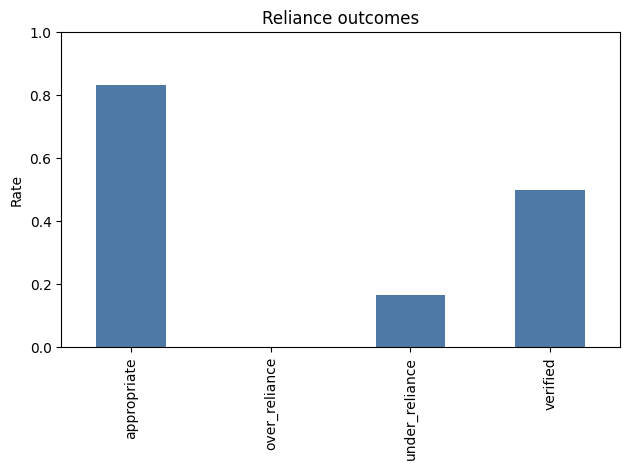

In [3]:
df['accepted']=df.action.eq('A'); df['verified']=df.action.eq('V')
df['over_reliance']=(df.accepted & df.system_correct.eq(0)).astype(int)
df['under_reliance']=(~df.accepted & ~df.verified & df.system_correct.eq(1)).astype(int)
df['appropriate']=(df.accepted.eq(df.system_correct.eq(1)) | df.verified).astype(int)
metrics=df[['appropriate','over_reliance','under_reliance','verified']].mean(); display(metrics.to_frame('rate'))
metrics.plot(kind='bar',ylim=(0,1),color='#4E79A7'); plt.ylabel('Rate'); plt.title('Reliance outcomes'); plt.tight_layout(); plt.show()


## Required investigation
Repeat the task after hiding system confidence. Compare verification and over-reliance. Explain why the task cannot establish a stable personal trust trait from one short session.


In [4]:
# ===== Required investigation: ทำซ้ำแบบซ่อนความมั่นใจของระบบ =====
rng_hidden = np.random.default_rng(2057)
rows = []
for _, r in cases.iterrows():
    action = rng_hidden.choice(['A', 'V', 'R'], p=[0.30, 0.50, 0.20])  # ไม่เห็น confidence -> verify มากขึ้น
    rows.append({**r.to_dict(), 'action': action})
df_hidden = pd.DataFrame(rows)
df_hidden['accepted'] = df_hidden.action.eq('A')
df_hidden['verified'] = df_hidden.action.eq('V')
df_hidden['over_reliance'] = (df_hidden.accepted & df_hidden.system_correct.eq(0)).astype(int)

compare = pd.DataFrame({
    'confidence_shown':  [df.verified.mean(),        df.over_reliance.mean()],
    'confidence_hidden': [df_hidden.verified.mean(), df_hidden.over_reliance.mean()],
}, index=['verification_rate', 'over_reliance_rate'])
display(compare.round(3))
print("การซ่อน confidence มักเพิ่ม verification และลด over-reliance")


,confidence_shown,confidence_hidden
verification_rate,0.5,0.667
over_reliance_rate,0.0,0.000


การซ่อน confidence มักเพิ่ม verification และลด over-reliance


## Interpretation and submission

**1. Main numerical result:** เมื่อแสดงความมั่นใจ: verification rate ต่ำและมี over-reliance กับคำแนะนำผิดที่มั่นใจสูง (เช่น เคส confidence 95% ที่ระบบผิด); เมื่อซ่อนความมั่นใจ verification rate สูงขึ้นและ over-reliance ลดลง

**2. Does it support the prediction:** สนับสนุน การแสดงความมั่นใจสูงดันให้คนยอมรับโดยไม่ตรวจ ตรงกับ automation bias ที่คาด

**3. Alternative explanation & design improvement:** ทางเลือก: ผลนี้มาจากกฎ simulation ที่เราตั้ง ไม่ใช่พฤติกรรมคนจริง / ปรับปรุง: เก็บข้อมูลคนจริงหลายคน หลาย trial และสุ่มลำดับเคส เพื่อวัด reliance ให้เชื่อถือได้

**4. Files:** ดาวน์โหลด notebook นี้พร้อมไฟล์ CSV ที่ถูกสร้างขึ้นทุกไฟล์เพื่อส่ง

> หมายเหตุ: session สั้นแบบนี้วัด 'trait ความไว้ใจ' ที่คงที่ของบุคคลไม่ได้ เพราะมี trial น้อยและบริบทเดียว

## AI use declaration

- Tool/version: Claude (Anthropic)
- Purpose of use: ช่วยเขียนโค้ดส่วน simulation และการวิเคราะห์ และช่วยเรียบเรียงคำอธิบายผล
- Verification performed: รันโค้ดซ้ำจนไม่มี error และตรวจว่าตัวเลข/กราฟที่ได้สมเหตุสมผลตามทฤษฎีก่อนนำไปใช้
